# Multi-catalog search: CSDA, NASA CMR and commercial vendor APIs

One call searches every configured catalog (STAC APIs and NASA CMR) for your sites, dates and filters, and returns one harmonized GeoDataFrame.

- Provider profiles: `lib/stac_providers.yaml` (no secrets)
- Credentials: INI file at `$STAC_CREDENTIALS` (default `/home/pmontesa/code/credentials.ini`), one section per vendor
- `csda-cmr` is NASA CMR's CSDA provider (Maxar legacy archive: WorldView, GeoEye; PlanetScope 3-band). Same columns as the STAC providers.
- Vendor rows get `in_csda` = True when CSDA returned the same `vendor_item_id` (e.g. `satl:outcome_id`) in the same search

In [1]:
import sys
sys.path.append('/home/pmontesa/code/csda_summaries/lib')

import importlib
import pandas as pd
import multistac
import multistac_plots
importlib.reload(multistac)
importlib.reload(multistac_plots)

pd.set_option('display.max_columns', 40)


## Providers and collections

In [2]:
multistac.list_providers()

,provider,label,api,enabled,auth,credentials_section,credentials_found,url,display_name
0,csda,NASA CSDA,stac,True,none,None,None,https://csdap.earthdata.nasa.gov/stac,CSDA STAC
1,satellogic,Satellogic,stac,True,satellogic,Satellogic_STAC_API,True,https://api.satellogic.com/v2/archive,Satellogic
2,csda-cmr,NASA CMR - CSDA provider (Maxar legacy archive...,cmr,True,none,None,None,https://cmr.earthdata.nasa.gov/search,Earthdata CMR – CSDA
3,hydrosat,Hydrosat,stac,False,oauth2_client_credentials,Hydrosat_STAC_API,True,https://stac.hydrosat.com,Hydrosat


All CSDA STAC collections, discovered from the API. Add IDs to `CSDA_EXCLUDE` to skip some, e.g. the radio-occultation collections (`spire`, `planetiq`, `geooptics`) or DEMs (`airbus-dem`, `maxar-sdx`, `pgc-earthdem`).

In [3]:
csda_collections = multistac.collections('csda')
CSDA_EXCLUDE = []  # e.g. ['spire', 'planetiq', 'geooptics']
CSDA_IDS = [c for c in csda_collections['id'] if c not in CSDA_EXCLUDE]
print(f'{len(CSDA_IDS)} of {len(csda_collections)} CSDA STAC collections:', ', '.join(CSDA_IDS))
csda_collections

23 of 23 CSDA STAC collections: umbra, desis, pixxel, planetiq, satellogic, geooptics, spire, iceye, airbus-dem, tomorrow, pgc-earthdem, maxar-sdx, capellaspace, airbus, maxar-legion, airbus-optical, ghgsat, blacksky, kuvaspace, mda, planet, ororatech, hydrosat


,id,title
0,umbra,Umbra
1,desis,DESIS
2,pixxel,Pixxel
3,planetiq,PlanetiQ
4,satellogic,Satellogic
5,geooptics,GeoOptics
6,spire,Spire
7,iceye,Iceye
8,airbus-dem,Airbus - DEM
9,tomorrow,Tomorrow


In [4]:
# multistac.collections('csda-cmr')  # includes granule counts
# multistac.collections('satellogic')
# multistac.queryables('csda', 'planet')
# multistac.sample_item('csda', 'airbus-optical')['properties']

## Search parameters

In [24]:
SITES = '/home/pmontesa/code/csda_summaries/sites/csda_sites_aoi.geojson'
SITE_NAME_FIELD = 'Site Name'
START, END = '2020-01-01', '2026-10-01'
MONTHS = None            # e.g. [6, 7, 8] for JJA only

PROVIDERS = {
    'csda':       CSDA_IDS,  # all CSDA STAC collections (see above); or a list, e.g. ['planet', 'maxar-legion']
    'satellogic': None,  # None -> default_collections from the profile
    'csda-cmr':   None,  # all CMR CSDA collections with granules
}
CLOUD_COVER_MAX = None     # None keeps collections without cloud cover (SAR, DEMs, radio occultation)
PROCESSING_LEVEL = None  # e.g. ['L1D_SR', 'ORT', 'LV2A']
PRODUCT_TYPE = None      # e.g. ['PSScene', 'MS-FS']

CACHE_DIR = '/explore/nobackup/people/pmontesa/stac_cache/multistac'

## Catalog overview

Catalog-wide first/last acquisition and total per collection (not limited to your sites). `in_window` = False means the collection has nothing in START-END, so it will return no rows. `total` is n/a where the API does not report counts (CSDA STAC).

In [25]:
catalog_overview = multistac.overview(PROVIDERS, START, END)
catalog_overview

,provider,collection,title,first,last,total,dates_from,in_window
0,csda,umbra,Umbra,2023-11-02,2026-10-08,n/a,items,True
1,csda,desis,DESIS,2018-08-30,2024-05-25,n/a,items,True
2,csda,pixxel,Pixxel,2025-06-21,2026-06-13,n/a,items,True
3,csda,planetiq,PlanetiQ,2024-01-18,2024-10-27,n/a,items,True
4,csda,satellogic,Satellogic,2021-02-02,2026-10-02,n/a,items,True
5,csda,geooptics,GeoOptics,2020-01-01,2021-04-30,n/a,items,True
6,csda,spire,Spire,2019-11-01,2025-08-09,n/a,items,True
7,csda,iceye,Iceye,2019-10-17,2026-10-10,n/a,items,True
8,csda,airbus-dem,Airbus - DEM,2025-09-19,2026-04-13,n/a,items,True
9,csda,tomorrow,Tomorrow,2023-06-24,2026-02-22,n/a,items,True


Catalog-wide acquisitions by year and month (Jan..Dec + total). Only catalogs that report counts (NASA CMR) get monthly cells; the plot shows the others (CSDA STAC) as a band from first to last acquisition.

In [26]:
catalog_months = multistac.overview_by_month(PROVIDERS, START, END)
catalog_months

No catalog counts from this API (use res.by_month()): csda/umbra, csda/desis, csda/pixxel, csda/planetiq, csda/satellogic, csda/geooptics, csda/spire, csda/iceye, csda/airbus-dem, csda/tomorrow, csda/pgc-earthdem, csda/maxar-sdx, csda/capellaspace, csda/airbus, csda/maxar-legion, csda/airbus-optical, csda/ghgsat, csda/blacksky, csda/kuvaspace, csda/mda, csda/planet, csda/ororatech, csda/hydrosat


,provider,collection,year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,total
0,csda-cmr,GE01_MSI_L1B,2020,6993,8809,11920,12230,12178,11977,10724,11214,9579,9386,9059,8354,122423
1,csda-cmr,GE01_MSI_L1B,2021,9558,10148,15176,14646,14075,11563,10282,10436,10502,9743,6683,5909,128721
2,csda-cmr,GE01_MSI_L1B,2022,6526,7305,8770,7854,8716,7973,8158,7347,3797,5755,3590,4969,80760
3,csda-cmr,GE01_MSI_L1B,2023,3241,6130,3904,6899,6978,6250,7901,7963,7312,9067,3746,4171,73562
4,csda-cmr,GE01_MSI_L1B,2024,3594,5502,5436,4605,6881,7942,8531,5882,1586,22,0,0,49981
5,csda-cmr,GE01_MSI_L2A,2020,0,0,0,0,0,0,5,0,0,0,0,0,5
6,csda-cmr,GE01_Pan_L1B,2020,5121,6768,10059,10151,9650,9288,8491,8877,6817,6372,6423,6075,94092
7,csda-cmr,GE01_Pan_L1B,2021,6430,7227,11851,9719,9132,7155,6162,6726,7034,5919,3927,3222,84504
8,csda-cmr,GE01_Pan_L1B,2022,3970,4170,4943,3931,4381,3789,3953,5081,3338,4465,3024,2420,47465
9,csda-cmr,GE01_Pan_L1B,2023,1393,3105,3113,5227,3881,3801,5649,5076,4909,2702,1096,1328,41280


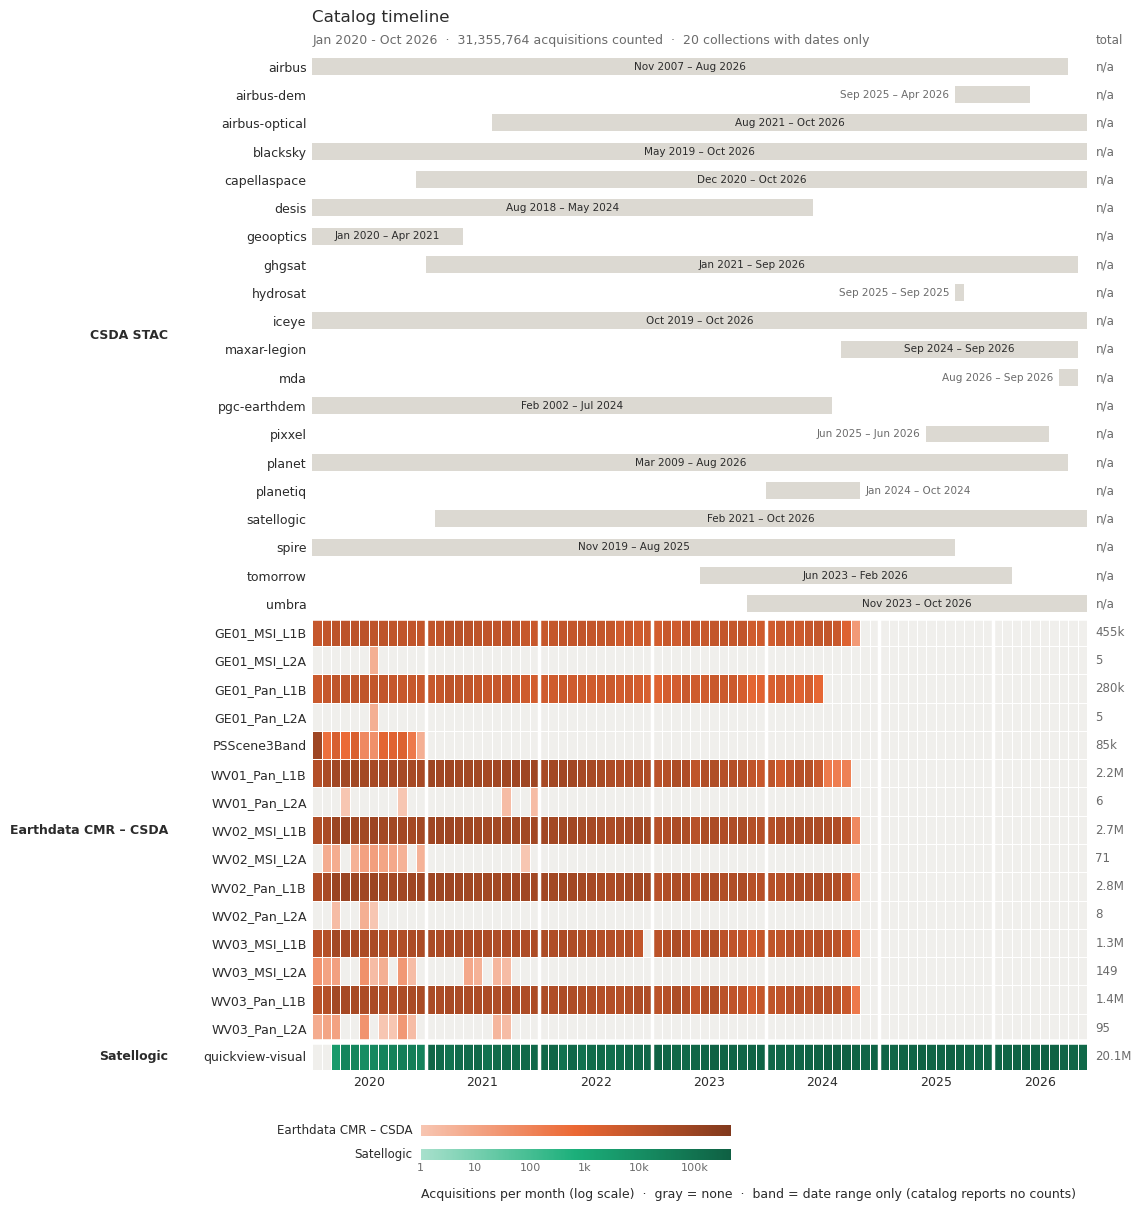

In [27]:
# Collections without counts (CSDA STAC) show their first-last date range as a band
multistac_plots.plot_month_heatmap(catalog_months, spans=catalog_overview, color_by='provider',
                                   start=START[:7], end=END[:7], title='Catalog timeline');

## Search

In [ ]:
%%time
res = multistac.search(
    SITES, START, END, PROVIDERS, months=MONTHS, site_name_field=SITE_NAME_FIELD,
    cloud_cover_max=CLOUD_COVER_MAX, processing_level=PROCESSING_LEVEL, product_type=PRODUCT_TYPE,
    cache_dir=CACHE_DIR,
)
res

searches:  13%|█▎        | 1181/9184 [22:03<101:17:45, 45.57s/it]

In [29]:
# Task log: status, item count and which filters ran server-side
print(res.log.status.value_counts())
res.log[res.log.status == 'failed']

cached      4919
searched    4256
failed         9
Name: status, dtype: int64


,provider,collection,site_name,interval,status,count,server_filters,error,seconds
8964,satellogic,quickview-visual,AZ Pima County,2025-01-01/2026-10-01,failed,0,eo:cloud_cover<=20 (cql2),satellogic: HTTP 502 for POST https://api.sate...,135.9
9018,satellogic,quickview-visual,Gobabeb,2025-01-01/2026-10-01,failed,0,eo:cloud_cover<=20 (cql2),satellogic: HTTP 502 for POST https://api.sate...,37.6
9019,satellogic,quickview-visual,Gobabeb TIR,2025-01-01/2026-10-01,failed,0,eo:cloud_cover<=20 (cql2),satellogic: HTTP 502 for POST https://api.sate...,62.8
9031,satellogic,quickview-visual,La Crau,2025-01-01/2026-10-01,failed,0,eo:cloud_cover<=20 (cql2),satellogic: HTTP 502 for POST https://api.sate...,100.7
9032,satellogic,quickview-visual,La Crau TIR,2025-01-01/2026-10-01,failed,0,eo:cloud_cover<=20 (cql2),satellogic: HTTP 502 for POST https://api.sate...,80.5
9039,satellogic,quickview-visual,Long Beach Docks,2025-01-01/2026-10-01,failed,0,eo:cloud_cover<=20 (cql2),satellogic: HTTP 502 for POST https://api.sate...,150.3
9046,satellogic,quickview-visual,Mexico City,2025-01-01/2026-10-01,failed,0,eo:cloud_cover<=20 (cql2),satellogic: HTTP 502 for POST https://api.sate...,31.5
9083,satellogic,quickview-visual,PICS Algeria-3,2025-01-01/2026-10-01,failed,0,eo:cloud_cover<=20 (cql2),satellogic: HTTP 502 for POST https://api.sate...,118.1
9130,satellogic,quickview-visual,Railroad Valley,2025-01-01/2026-10-01,failed,0,eo:cloud_cover<=20 (cql2),satellogic: HTTP 502 for POST https://api.sate...,134.3


In [29]:
res.summary()

Exception ignored in: <function tqdm.__del__ at 0x14d6c5fd35e0>
Traceback (most recent call last):
  File "/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/tqdm/std.py", line 1144, in __del__
    def __del__(self):
KeyboardInterrupt: 


KeyboardInterrupt: 

Acquisitions found by this search, by year and month (unique items, all providers).

In [ ]:
search_months = res.by_month()
search_months

In [ ]:
multistac_plots.plot_month_heatmap(search_months, color_by='provider',
                                   title='Acquisitions found at the search sites');

## Slice and dice

Every row has `affiliation` (data owner, e.g. Vantor), `constellation` (e.g. Legion) and `sensor` (e.g. LG01), normalized across catalogs via `lib/sensor_catalog.yaml`. Group monthly counts by any columns with `res.by_month([...])`, or `multistac.month_table(gdf, [...])` for a filtered or saved GeoDataFrame.

Plot options: `rows=` (row grouping, outermost first), `color_by=` (one hue per value, max 8), `cmap=` (`'blue'` default, or any matplotlib map e.g. `'viridis'`, `'turbo'`), `start=`/`end=`, `max_rows=`.

In [ ]:
by_constellation = res.by_month(['affiliation', 'constellation'])
multistac_plots.plot_month_heatmap(by_constellation, color_by='affiliation',
                                   title='Acquisitions by affiliation and constellation');

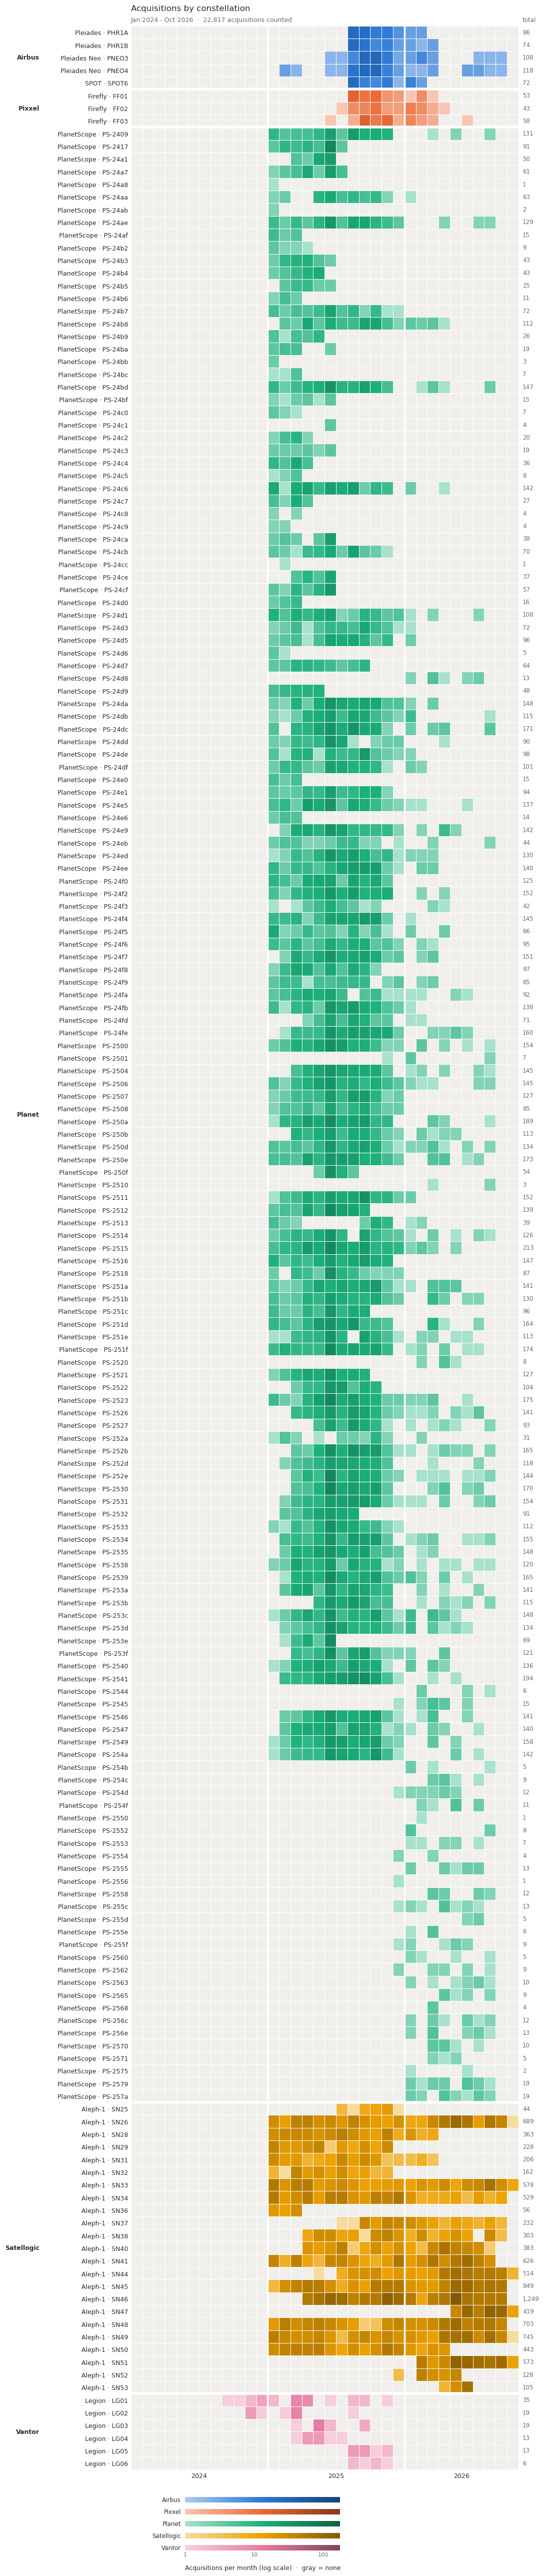

In [23]:
by_constellation = multistac.month_table(res.gdf, ['affiliation', 'constellation'])
multistac_plots.plot_month_heatmap(by_sensor, color_by='affiliation', max_rows=200,
                                   title='Acquisitions by constellation');

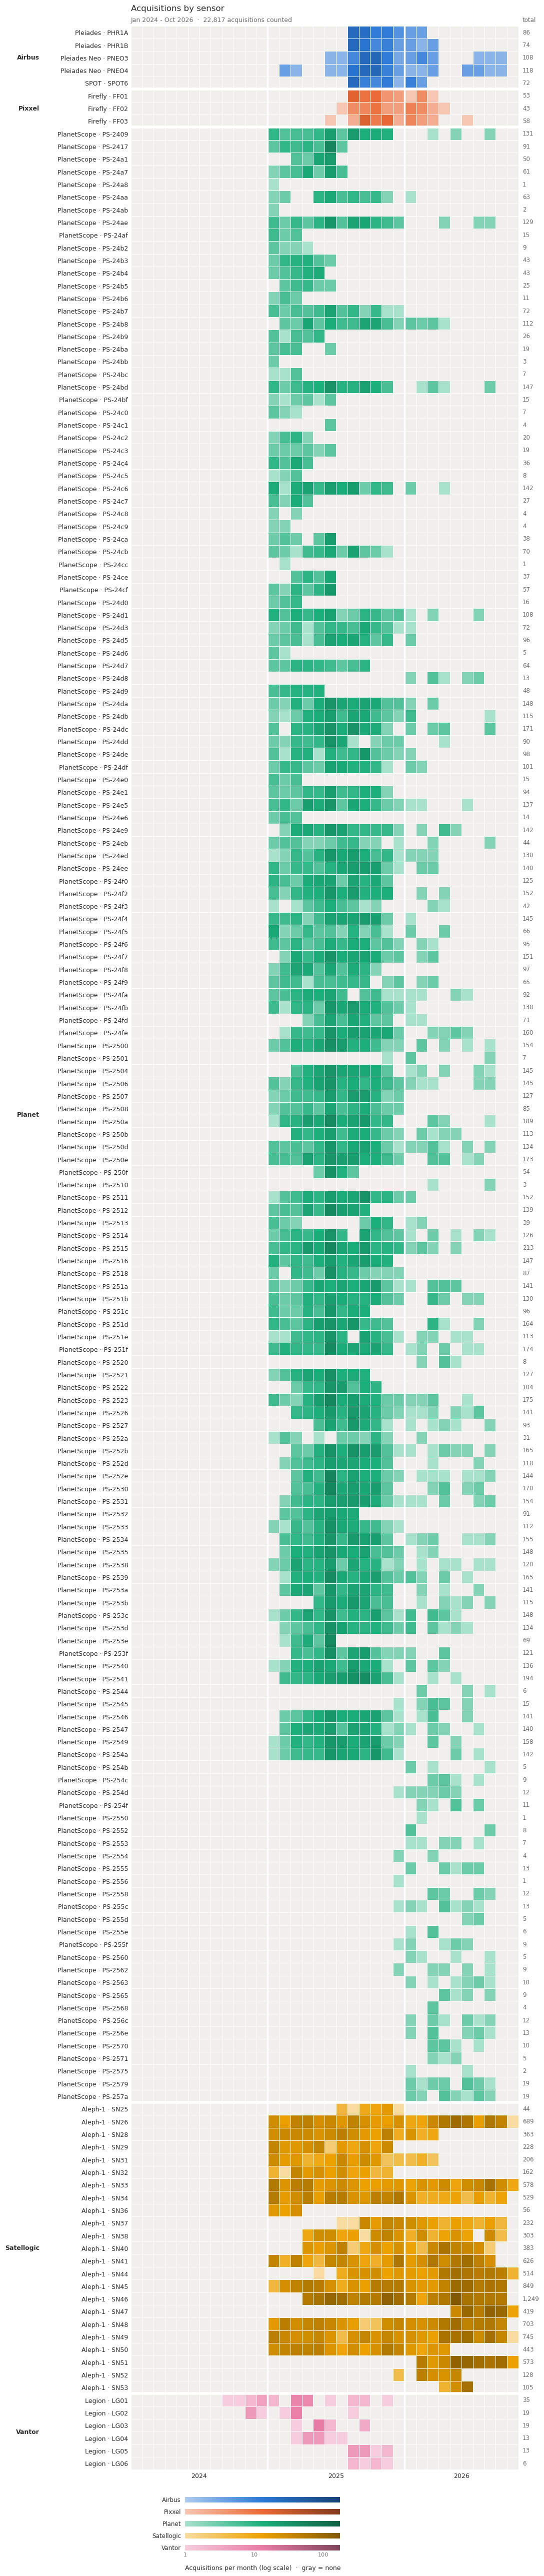

In [22]:
# Individual satellites; PlanetScope has hundreds, so leave it out here
#g = res.gdf[res.gdf.constellation != 'PlanetScope']
by_sensor = multistac.month_table(res.gdf, ['affiliation', 'constellation', 'sensor'])
multistac_plots.plot_month_heatmap(by_sensor, color_by='affiliation', max_rows=200,
                                   title='Acquisitions by sensor');

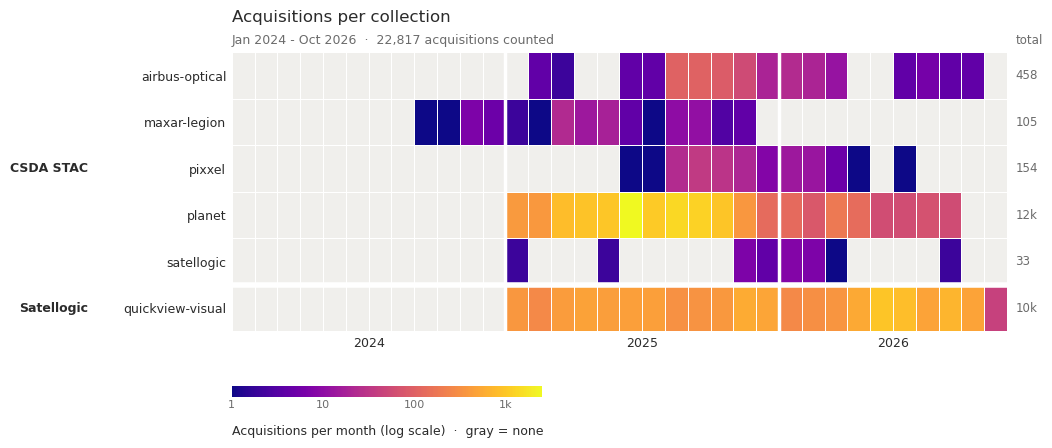

In [20]:
# Any matplotlib colormap
multistac_plots.plot_month_heatmap(res.by_month(['provider', 'collection']), cmap='plasma',
                                   title='Acquisitions per collection');

In [17]:
res.gdf[multistac.COMMON_COLUMNS].head()

,provider,affiliation,constellation,sensor,collection,id,datetime,site_name,cloud_cover,processing_level,product_type,platform,instrument,gsd,off_nadir,incidence_angle,view_azimuth,sun_elevation,sun_azimuth,vendor_item_id,in_csda,stac_self_href
0,csda,Planet,PlanetScope,PS-2506,planet,PSScene-20250202_182614_22_2506,2025-02-02 18:26:14.227122+00:00,AZ Coconino 1,0.0,None,PSScene,2506,PSB.SD,3.8,0.3,NaN,246.9,35.8,158.3,PSScene-20250202_182614_22_2506,True,https://csdap.earthdata.nasa.gov/stac/collecti...
1,csda,Planet,PlanetScope,PS-251f,planet,PSScene-20250202_182829_36_251f,2025-02-02 18:28:29.360249+00:00,AZ Coconino 1,0.0,None,PSScene,251f,PSB.SD,3.8,4.8,NaN,277.4,35.5,158.3,PSScene-20250202_182829_36_251f,True,https://csdap.earthdata.nasa.gov/stac/collecti...
2,csda,Planet,PlanetScope,PS-251f,planet,PSScene-20250202_182831_66_251f,2025-02-02 18:28:31.669749+00:00,AZ Coconino 1,0.0,None,PSScene,251f,PSB.SD,3.8,4.8,NaN,277.4,35.7,158.2,PSScene-20250202_182831_66_251f,True,https://csdap.earthdata.nasa.gov/stac/collecti...
3,csda,Planet,PlanetScope,PS-253c,planet,PSScene-20250601_183833_73_253c,2025-06-01 18:38:33.736418+00:00,AZ Coconino 1,4.0,None,PSScene,253c,PSB.SD,3.9,2.1,NaN,276.6,73.8,138.5,PSScene-20250601_183833_73_253c,True,https://csdap.earthdata.nasa.gov/stac/collecti...
4,csda,Planet,PlanetScope,PS-24cf,planet,PSScene-20250606_180731_21_24cf,2025-06-06 18:07:31.219394+00:00,AZ Coconino 1,0.0,None,PSScene,24cf,PSB.SD,3.0,2.8,NaN,102.3,69.4,120.9,PSScene-20250606_180731_21_24cf,True,https://csdap.earthdata.nasa.gov/stac/collecti...


## Vendor items not yet acquired by CSDA

In [18]:
not_in_csda = res.gdf[res.gdf.in_csda == False]
not_in_csda.groupby(['site_name', 'collection', 'processing_level']).size()

site_name        collection        processing_level
Albuquerque      quickview-visual  QUICKVIEW_VISUAL    588
Ankara           quickview-visual  QUICKVIEW_VISUAL    293
Baotou           quickview-visual  QUICKVIEW_VISUAL    963
Belo Horizonte   quickview-visual  QUICKVIEW_VISUAL     47
Boston           quickview-visual  QUICKVIEW_VISUAL     26
                                                      ... 
Shadnagar        quickview-visual  QUICKVIEW_VISUAL    595
Singapore        quickview-visual  QUICKVIEW_VISUAL    112
Suramadu Bridge  quickview-visual  QUICKVIEW_VISUAL     49
Tianjin Docks    quickview-visual  QUICKVIEW_VISUAL    353
Valencia         quickview-visual  QUICKVIEW_VISUAL    118
Length: 69, dtype: int64

## Refilter locally without searching again

In [19]:
clear_l1d = multistac.apply_filters(res.gdf, cloud_cover_max=5, processing_level=['L1D', 'L1D_SR'],
                                    where=lambda g: g.off_nadir < 15)
clear_l1d.groupby(['provider', 'site_name']).size()

provider  site_name              
csda      Albuquerque                3
          Baotou                     2
          Casablanca                 3
          Catania                    3
          OPERA CR Array P288_CRe    1
          OPERA CR Array P288_CRw    1
          PICS Libya-4               2
          RCRA                       1
          RCRA 0                     1
          RCRA 1                     1
          RCRA 10                    1
          RCRA 11                    1
          RCRA 13                    1
          RCRA 14                    1
          RCRA 15                    1
          RCRA 16                    1
          RCRA 17                    1
          RCRA 18                    1
          RCRA 19                    1
          RCRA 2                     1
          RCRA 20                    1
          RCRA 21                    1
          RCRA 22                    1
          RCRA 23                    1
          RCRA 24             

## Save

In [ ]:
# Writes .gpkg, .csv, _items.geojson and _log.csv
# res.save('/explore/nobackup/people/pmontesa/stac_cache/multistac/out/eval_sites_2025')